# 03 - Uplift / CATE Modeling

Trains S-Learner, T-Learner, X-Learner, DR-Learner (EconML meta-learners, LightGBM base learners) and a
Causal Forest (EconML `CausalForestDML`) on a 3,000,000-row stratified sample. Evaluation uses a held-out
30% split. Qini and AUUC are reported per 100,000 observations with paired bootstrap intervals.

In [1]:
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
from src.utils.config import TABLES_DIR, FIGURES_DIR, REPORT_DIR

## Model Fit Times

In [2]:
pd.read_csv(TABLES_DIR / "uplift_model_fit_times.csv", index_col=0)

,fit_time_seconds
S-Learner,12.016729
T-Learner,10.286513
X-Learner,24.850614
DR-Learner,50.354507
Causal Forest,678.988637


## Model Comparison: Qini Coefficient & AUUC

In [3]:
pd.read_csv(TABLES_DIR / "uplift_model_comparison.csv")

,model,qini_coefficient,auuc_score,average_predicted_uplift
0,DR-Learner,327.213864,325.482779,0.000992
1,S-Learner,326.568995,331.352278,0.000906
2,Causal Forest,275.261410,284.918216,0.000963
3,X-Learner,238.054048,235.494556,0.001014
4,T-Learner,158.457764,145.890470,0.001023


## Bootstrap Uncertainty

In [4]:
pd.read_csv(TABLES_DIR / "uplift_model_uncertainty.csv")

,model,qini_coefficient,qini_per_100k,qini_ci_low_per_100k,qini_ci_high_per_100k,auuc_score,auuc_per_100k,auuc_ci_low_per_100k,auuc_ci_high_per_100k,bootstrap_repetitions
0,DR-Learner,327.213864,36.357056,23.387866,47.170892,325.482779,36.164713,21.063454,49.444380,200
1,S-Learner,326.568995,36.285404,23.785099,47.317943,331.352278,36.816879,20.916655,49.314575,200
2,Causal Forest,275.261410,30.584567,16.831475,41.228794,284.918216,31.657544,15.453657,44.207741,200
3,X-Learner,238.054048,26.450420,15.223724,36.627919,235.494556,26.166033,12.049515,39.075167,200
4,T-Learner,158.457764,17.606399,3.977356,28.108231,145.890470,16.210034,-0.193248,28.336984,200


In [5]:
pairs = pd.read_csv(TABLES_DIR / "uplift_model_pairwise_bootstrap.csv")
pairs[
    ((pairs["model_a"] == "S-Learner") & pairs["model_b"].isin(["DR-Learner", "X-Learner", "T-Learner"]))
    | ((pairs["model_a"] == "DR-Learner") & pairs["model_b"].isin(["X-Learner", "T-Learner"]))
]

,model_a,model_b,qini_difference_per_100k,qini_difference_ci_low,qini_difference_ci_high,probability_qini_a_gt_b,auuc_difference_per_100k,auuc_difference_ci_low,auuc_difference_ci_high,probability_auuc_a_gt_b,bootstrap_repetitions
0,S-Learner,T-Learner,18.679005,10.564948,27.512435,1.000,20.606845,10.272012,30.164672,1.000,200
1,S-Learner,X-Learner,9.834983,1.662385,16.740251,0.985,10.650846,0.218978,18.485426,0.980,200
2,S-Learner,DR-Learner,-0.071652,-5.551667,4.475747,0.530,0.652166,-6.130454,5.622552,0.545,200


Raw Qini and AUUC scale with the number of observations, so comparisons across datasets use the per-100,000
columns. S-Learner and DR-Learner have nearly identical point estimates; their paired bootstrap difference
includes zero. Both separate more clearly from X-Learner and T-Learner. These percentile intervals condition
on the fitted scores and do not include model-refitting uncertainty.

## Qini Curves

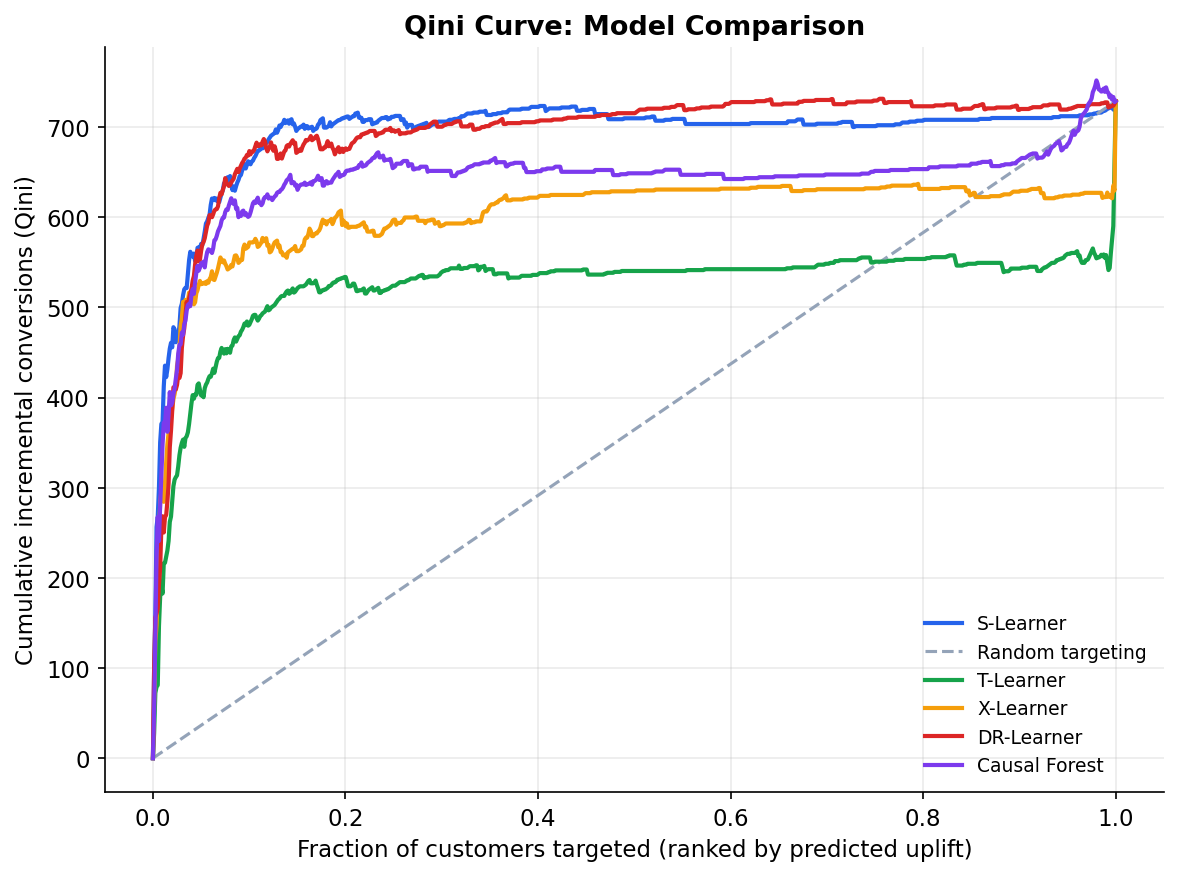

In [6]:
display(Image(filename=str(FIGURES_DIR / "qini_curves_all_models.png")))

## Incremental Gain Curves

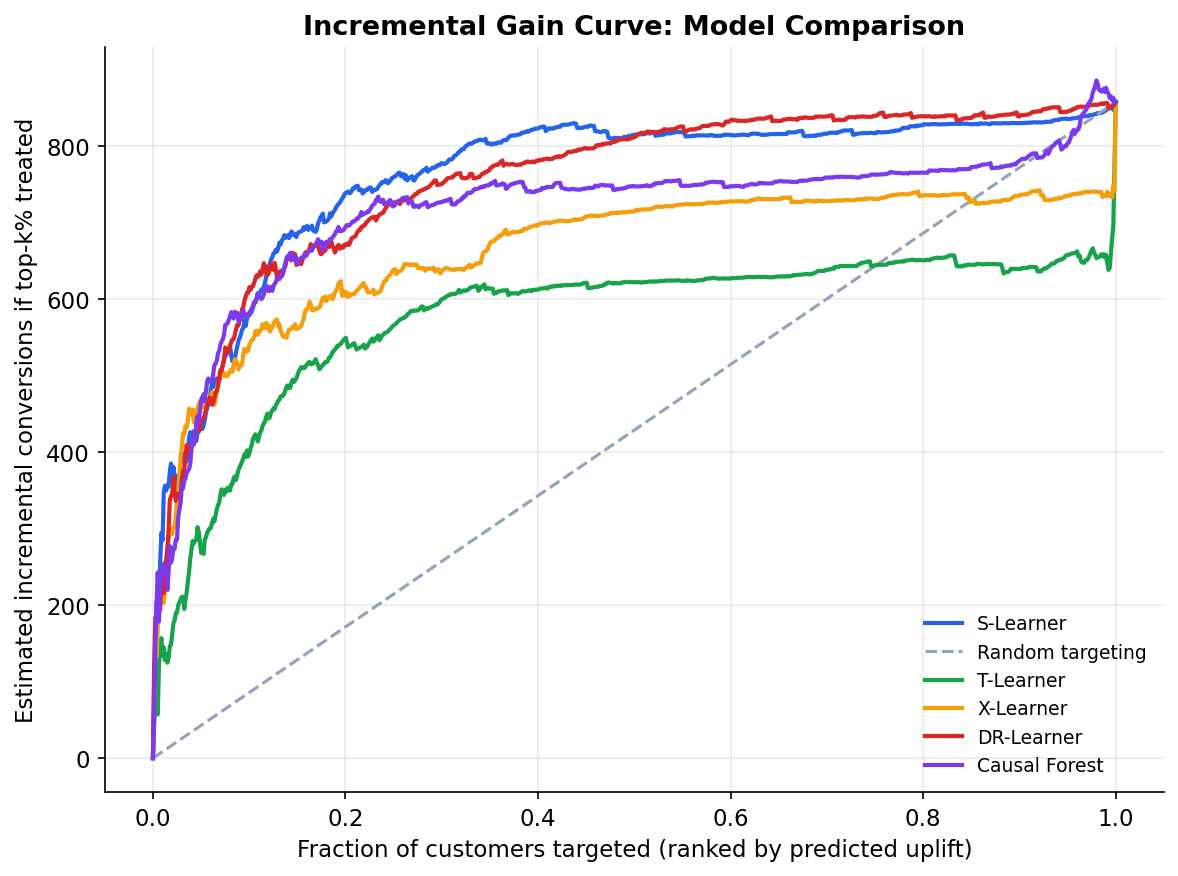

In [7]:
display(Image(filename=str(FIGURES_DIR / "gain_curves_all_models.png")))

## Who Benefits, Who May Be Harmed

In [8]:
pd.read_csv(TABLES_DIR / "segment_profile_top_vs_bottom_uplift.csv")

,segment,n,n_treated,n_control,mean_predicted_uplift,actual_treated_rate,actual_control_rate,actual_uplift_ci_low,actual_uplift_ci_high,actual_uplift,mean_f0,mean_f1,mean_f2,mean_f3,mean_f4,mean_f5,mean_f6,mean_f7,mean_f8,mean_f9,mean_f10,mean_f11
0,Top 10% predicted uplift (target these),45000,38778,6222,0.008541,0.026278,0.019608,0.002611,0.010230,0.006670,16.625230,10.133612,8.468868,2.353332,10.805095,3.686470,-9.178179,5.801340,3.825108,28.680584,5.577841,-0.190617
1,Bottom 10% predicted uplift (avoid targeting),45001,38095,6906,-0.000159,0.000998,0.000579,-0.000530,0.000931,0.000418,22.114744,10.064331,8.392146,4.419040,10.308955,4.038336,-4.676633,5.127727,3.956672,13.801835,5.313820,-0.169506


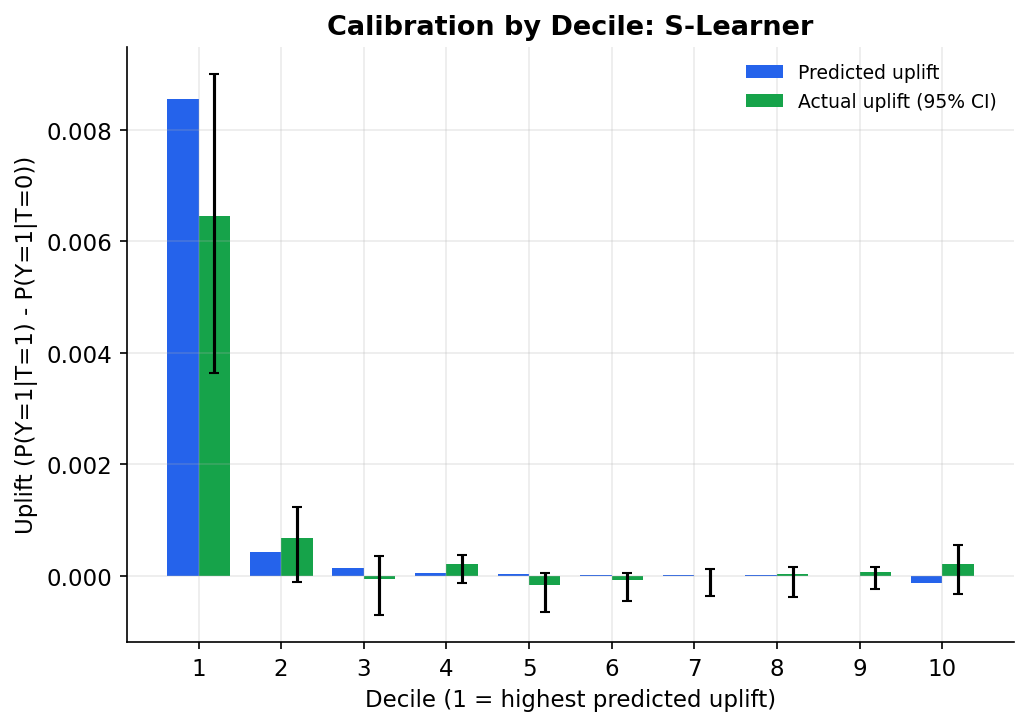

In [9]:
display(Image(filename=str(FIGURES_DIR / "calibration_S-Learner.png")))

The top S-Learner decile has positive observed uplift and a 95% interval above zero. The bottom-decile point
estimate is 0.042 percentage points and its interval includes zero. Several calibration deciles have small
negative point estimates, but their intervals also include zero; the data therefore do not establish either
harm or safety within those deciles.